# Lesson 20 - Balanced merged classes, an SVM, four classes, and wider distance buckets

Four questions after lesson 19:

1. **Cargo + tanker has 10 hours of audio, the other classes 5. Was it balanced?** The score (balanced accuracy)
   always was: every class counts the same. Training was not: lesson 16 kept the six-class weights, so the merged
   class counted twice as much. Here every merged class gets the same total weight, split equally between its
   original classes, and inside those equally between ships.
2. **Does an SVM do better than gradient boosting** on the engineered features?
3. **Four classes:** fishing boats and tugs merged into "fishing + tug" (small working boats), next to background,
   cargo + tanker and pleasure craft.
4. **Distance with 300 m and 400 m buckets** instead of 250 m.

Same folds, test ships and 144 engineered features as lessons 13-19; every choice made on validation.

```
python src/merged_classes.py                  # questions 1-3 -> runs/merged_classes/ (CPU, about 12 minutes)
python src/distance_classical.py --width 300  # question 4 -> runs/distance_classical_300m/
python src/distance_classical.py --width 400
```

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix
import five_classes as F5
import merged_classes as M
from paths import RUNS_DIR

res = pd.DataFrame(json.loads((M.OUT_DIR / "results.json").read_text())["results"])
preds = pd.read_parquet(M.OUT_DIR / "predictions.parquet")
old = pd.DataFrame(json.loads((F5.OUT_DIR / "results.json").read_text())["results"])
pd.set_option("display.width", 160)

## 1-3. Balanced merged classes, SVM, four classes

Test folds, mean ± spread over 5 folds. The first row is lesson 16 (merged class counted double in training).

In [2]:
def fmt(g, col):
    return (100 * g[col].mean()).round(1).astype(str) + " ± " + (100 * g[col].std()).round(1).astype(str)


old16 = old[(old.features == "engineered") & (old.model == "gradient boosting")].assign(
    grouping="5 classes", model="gradient boosting, lesson 16 weights")
both = pd.concat([old16, res])
g = both.groupby(["grouping", "model"], sort=False)
table = pd.DataFrame({"per clip": fmt(g, "balanced_accuracy"), "per ship": fmt(g, "per_ship_balanced_accuracy")})
print(table.to_string())

rec = pd.DataFrame(list(res.per_class_recall)).assign(grouping=res.grouping, model=res.model)
print("\nrecall per class, per clip (%):")
print((100 * rec.groupby(["grouping", "model"]).mean()).round(1).to_string())

                                                  per clip    per ship
grouping  model                                                       
5 classes gradient boosting, lesson 16 weights  69.9 ± 1.3  78.9 ± 2.2
          gradient boosting                     70.0 ± 1.2  78.7 ± 2.9
          SVM                                   69.9 ± 1.4  77.0 ± 2.1
4 classes gradient boosting                     80.2 ± 1.3  86.8 ± 0.5
          SVM                                   79.8 ± 1.2  85.4 ± 0.6

recall per class, per clip (%):
                             background  cargo + tanker  fishing  pleasurecraft   tug  fishing + tug
grouping  model                                                                                     
4 classes SVM                      86.3            95.3      NaN           66.0   NaN           71.7
          gradient boosting        85.8            95.8      NaN           65.9   NaN           73.5
5 classes SVM                      85.8            94.7     42.0  

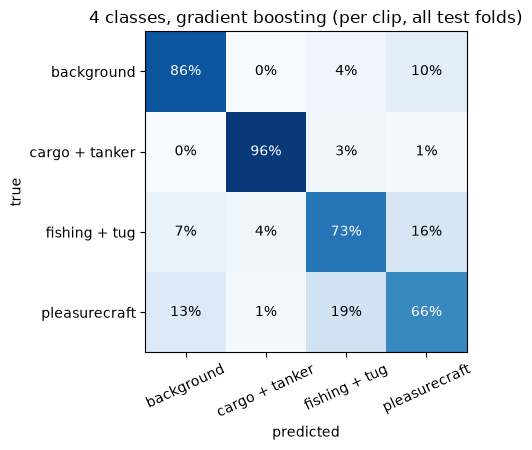

In [3]:
p = preds[(preds.grouping == "4 classes") & (preds.model == "gradient boosting")]
names = list(M.GROUPINGS["4 classes"])
cm = confusion_matrix(p.y, p[[f"p_{c}" for c in names]].to_numpy().argmax(1), normalize="true")
fig, ax = plt.subplots(figsize=(5.5, 4.6))
ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm[i, j]:.0%}", ha="center", va="center", color="white" if cm[i, j] > 0.5 else "black")
ax.set_xticks(range(4), names, rotation=25); ax.set_yticks(range(4), names)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("4 classes, gradient boosting (per clip, all test folds)"); plt.tight_layout(); plt.show()

- **Balancing the merged class changes nothing measurable:** 70.0 % per clip and 78.7 % per ship, against 69.9 %
  and 78.9 % with the double weight. The merged class was already right 95-96 % of the time.
- **The SVM is no better:** 69.9 % per clip (the same) and 77.0 % per ship (1.7 points lower) for five classes;
  79.8 % / 85.4 % against 80.2 % / 86.8 % for four. Validation chose C = 1 on every fold.
- **Four classes reach 80.2 % per clip and 86.8 % per ship** with gradient boosting, the least spread of any run
  (± 0.5 per ship). Fishing + tug is right 73.5 % of the time, pleasure craft 65.9 %: the weakest class is now
  pleasure craft, mostly confused with background and the working boats.
- Like the cargo + tanker merge, this changes the question and needs the professor's agreement.

## 4. Distance buckets of 250, 300 and 400 m

In [4]:
rows = []
for w in (250, 300, 400):
    d = RUNS_DIR / ("distance_classical" if w == 250 else f"distance_classical_{w}m")
    s = json.loads((d / "results.json").read_text())
    clf = pd.DataFrame([r["classifier"] for r in s["results"]]).mean()
    reg = pd.DataFrame([r["regression_binned"] for r in s["results"]]).mean()
    mae = pd.DataFrame([r["regression"] for r in s["results"]]).mae_m.mean()
    rows.append({"bucket": f"{w} m", "buckets": len(s["buckets"]), "chance (%)": round(100 / len(s["buckets"]), 1),
                 "features": s["chosen_features"], "classifier exact (%)": round(100 * clf.exact, 1),
                 "classifier exact or next (%)": round(100 * clf.near, 1),
                 "regression exact (%)": round(100 * reg.exact, 1),
                 "regression exact or next (%)": round(100 * reg.near, 1), "mean error (m)": round(mae)})
print(pd.DataFrame(rows).set_index("bucket").to_string())

        buckets  chance (%)             features  classifier exact (%)  classifier exact or next (%)  regression exact (%)  regression exact or next (%)  mean error (m)
bucket                                                                                                                                                                  
250 m         8        12.5       all engineered                  32.8                          69.9                  31.5                          75.2             258
300 m         7        14.3  MFCC 1-8 + the rest                  37.2                          75.0                  37.4                          80.9             260
400 m         5        20.0  MFCC 1-8 + the rest                  47.0                          85.0                  45.0                          90.5             260


- **Wider buckets are easier, as expected:** exact bucket 32.8 % (250 m), 37.2 % (300 m), 47.0 % (400 m); exact
  or next bucket with the regression 75.2 %, 80.9 % and 90.5 %.
- **The distance itself is not estimated better:** the mean error stays about 260 m. A wider bucket only asks a
  looser question. With 400 m buckets, "right or next" means within about 400-800 m.
- For 300 and 400 m the validation folds picked the reduced set (MFCC 1-8 + the rest, 111 numbers); for 250 m all
  144.

## What it means

| Test, 5 folds | Per clip | Per ship |
|---|---|---|
| 6 classes, gradient boosting (lesson 13) | 61.9 % | 70.5 % |
| 5 classes, cargo + tanker, balanced weights | 70.0 % | 78.7 % |
| 5 classes, SVM | 69.9 % | 77.0 % |
| **4 classes, + fishing + tug, gradient boosting** | **80.2 %** | **86.8 %** |

- Balancing the 10-hour merged class was the right thing to do but changes the result by less than the fold
  spread.
- The SVM matches gradient boosting per clip and is slightly worse per ship; gradient boosting stays.
- Each merge of two classes that sound alike adds about 10 points. The question it answers gets coarser each time,
  so which grouping to report is for the professor to decide.